<a href="https://colab.research.google.com/github/Sibgat-git/Medical-cost---Risk-Profiling-Linear-vs-Logistic-regression/blob/main/Medical_cost_%26_Risk_Profiling_Linear_vs_Logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error , r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("insurance.csv")

df.head()




,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


Text(0.5, 1.0, 'Feature Correlation Matrix')

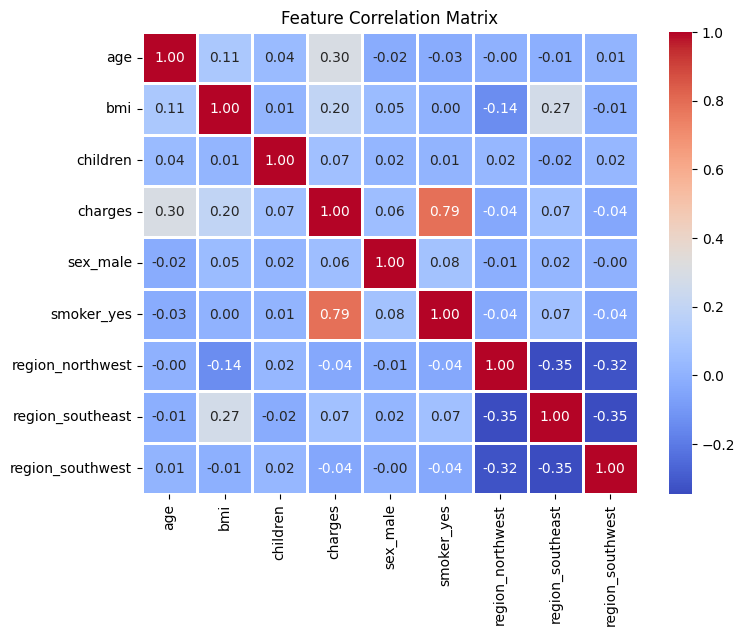

In [2]:
print(df.isnull().sum())

df_encoded = pd.get_dummies(df, drop_first = True)
plt.figure(figsize=(8,6))

sns.heatmap(
    df_encoded.corr(),annot=True, cmap="coolwarm" ,fmt = ".2f", linewidth = 1
)

plt.title("Feature Correlation Matrix")


### Exploratory Data Analysis (EDA) Summary

Based on the correlation matrix generated above:
* **Smoker (`smoker_yes`)** has an extremely high positive correlation (**0.79**) with `charges`. This shows that smoking status is the primary cost driver for medical charges.
* **Age** (**0.30**) and **BMI** (**0.20**) also show moderate positive correlations with `charges`.

### Cost Prediction (Linear Regression)

We will preprocess the features, train a Linear Regression model to predict charges, and evaluate its performance using $R^2$ and RMSE.

In [3]:
# Prepare features and target variable
X = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on test data
y_pred = lr_model.predict(X_test)

# Calculate metrics
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Linear Regression Performance:")
print(f"R^2 Score: {r2:.4f}")
print(f"RMSE: ${rmse:.2f}")

Linear Regression Performance:
R^2 Score: 0.7836
RMSE: $5796.28


###  Risk Classification (Logistic Regression)

We will flip the problem to predict the smoking status (`smoker_yes`) using Logistic Regression, and display the accuracy and confusion matrix.

Logistic Regression Performance:
Accuracy: 96.64%


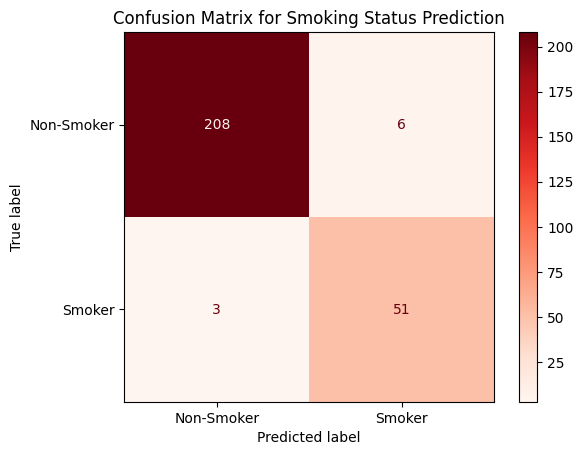

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Prepare features and target variable (predicting smoker_yes)
X_clf = df_encoded.drop(columns=['smoker_yes'])
y_clf = df_encoded['smoker_yes']

# Split into training and testing sets
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42)

# Train Logistic Regression model
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_c, y_train_c)

# Predictions
y_pred_c = log_reg.predict(X_test_c)

# Metrics
accuracy = accuracy_score(y_test_c, y_pred_c)
cm = confusion_matrix(y_test_c, y_pred_c)

print(f"Logistic Regression Performance:")
print(f"Accuracy: {accuracy * 100:.2f}%")

# Plot Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Smoker', 'Smoker'])
disp.plot(cmap='Reds')
plt.title("Confusion Matrix for Smoking Status Prediction")
plt.show()

Looking at this specific matrix for predicting whether someone is a Smoker or Non-Smoker, The results show:

Top-Left (208): True Negatives (TN). There were 208 people who are actually non-smokers, and the model correctly predicted they are non-smokers.

Bottom-Right (51): True Positives (TP). There were 51 people who are actually smokers, and the model correctly predicted they are smokers.

Top-Right (6): False Positives (FP). There were 6 people who are actually non-smokers, but the model incorrectly flagged them as smokers.

Bottom-Left (3): False Negatives (FN). There were 3 people who are actually smokers, but the model missed them and predicted they are non-smokers.

Overall, the diagonal from top-left to bottom-right (208 + 51 = 259) represents all the correct predictions, while the other diagonal (6 + 3 = 9) represents the errors.

Out of 268 total people in the test set, getting 259 correct means an accuracy of 96.64%.



### Feature Engineering

We will create an interaction term `bmi_smoker` (multiplying BMI by smoking status) to capture how the combination of high BMI and smoking impacts insurance costs.

In [5]:
# Create interaction term
df_engineered = df_encoded.copy()
df_engineered['bmi_smoker'] = df_engineered['bmi'] * df_engineered['smoker_yes']

# Prepare features and target variable with the interaction term
X_eng = df_engineered.drop(columns=['charges'])
y_eng = df_engineered['charges']

# Split data
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_eng, y_eng, test_size=0.2, random_state=42)

# Train updated model
lr_model_eng = LinearRegression()
lr_model_eng.fit(X_train_e, y_train_e)

# Predict
y_pred_e = lr_model_eng.predict(X_test_e)

# Calculate updated metrics
r2_e = r2_score(y_test_e, y_pred_e)
rmse_e = np.sqrt(mean_squared_error(y_test_e, y_pred_e))

print(f"Linear Regression (with Interaction Term) Performance:")
print(f"R^2 Score: {r2_e:.4f} (Previous: {r2:.4f})")
print(f"RMSE: ${rmse_e:.2f} (Previous: ${rmse:.2f})")

Linear Regression (with Interaction Term) Performance:
R^2 Score: 0.8653 (Previous: 0.7836)
RMSE: $4573.81 (Previous: $5796.28)


### Interactive Smoker Predictor

Use the sliders and dropdowns below to input person details and predict the probability of them being a smoker using our Logistic Regression model.

In [6]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Create input widgets
age_widget = widgets.IntSlider(value=30, min=18, max=100, step=1, description='Age:')
bmi_widget = widgets.FloatSlider(value=25.0, min=10.0, max=60.0, step=0.1, description='BMI:')
children_widget = widgets.IntSlider(value=0, min=0, max=10, step=1, description='Children:')
charges_widget = widgets.FloatSlider(value=10000.0, min=1000.0, max=65000.0, step=100.0, description='Charges ($):')
sex_widget = widgets.Dropdown(options=['male', 'female'], value='female', description='Sex:')
region_widget = widgets.Dropdown(options=['northeast', 'northwest', 'southeast', 'southwest'], value='southwest', description='Region:')

predict_button = widgets.Button(description="Predict Smoking Status", button_style='info')
output_widget = widgets.Output()

def make_prediction(b):
    with output_widget:
        clear_output()
        # Construct input DataFrame matching X_clf structure
        input_data = pd.DataFrame({
            'age': [age_widget.value],
            'bmi': [bmi_widget.value],
            'children': [children_widget.value],
            'charges': [charges_widget.value],
            'sex_male': [1 if sex_widget.value == 'male' else 0],
            'region_northwest': [1 if region_widget.value == 'northwest' else 0],
            'region_southeast': [1 if region_widget.value == 'southeast' else 0],
            'region_southwest': [1 if region_widget.value == 'southwest' else 0]
        })

        # Reorder columns to match model expectations exactly
        input_data = input_data[X_test_c.columns]

        # Predict probability
        prob = log_reg.predict_proba(input_data)[0][1] * 100

        print(f"Predicted Probability of being a Smoker: {prob:.2f}%")
        if prob >= 50:
            print("Classification: likely a SMOKER")
        else:
            print("Classification: likely a NON-SMOKER")

predict_button.on_click(make_prediction)

# Display Widgets
input_container = widgets.VBox([age_widget, bmi_widget, children_widget, charges_widget, sex_widget, region_widget, predict_button])
display(input_container, output_widget)

Output()

## Advanced Risk Profiling & Medical Cost Stratification

To profile risk clinically, we can categorize individuals into distinct risk tiers based on their key cost drivers:
1. **High Risk**: Smokers with a BMI of 30 or above (Clinically Obese).
2. **Moderate Risk**: Smokers with a BMI under 30 OR Non-smokers with a BMI of 30 or above.
3. **Low Risk**: Non-smokers with a BMI under 30.

Let's implement this profiling, calculate the average medical costs for each tier, and visualize the cost distributions.

In [9]:
def assign_risk_profile(row):
    is_smoker = row['smoker'] == 'yes'
    is_obese = row['bmi'] >= 30

    if is_smoker and is_obese:
        return 'High Risk'
    elif is_smoker or is_obese:
        return 'Moderate Risk'
    else:
        return 'Low Risk'

# Apply risk profiling to the original dataframe
df_profiled = df.copy()
df_profiled['Risk Profile'] = df_profiled.apply(assign_risk_profile, axis=1)

# Calculate statistics per risk profile
profile_summary = df_profiled.groupby('Risk Profile').agg(
    patient_count=('charges', 'count'),
    average_charges=('charges', 'mean'),
    median_charges=('charges', 'median')
).reindex(['Low Risk', 'Moderate Risk', 'High Risk'])

display(profile_summary)

,patient_count,average_charges,median_charges
Risk Profile,,,
Low Risk,502,7977.029520,6761.61525
Moderate Risk,691,11180.097894,9800.88820
High Risk,145,41557.989840,40904.19950


/tmp/ipykernel_3823/1388088077.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_profiled, x='Risk Profile', y='charges', order=['Low Risk', 'Moderate Risk', 'High Risk'], palette='Reds')


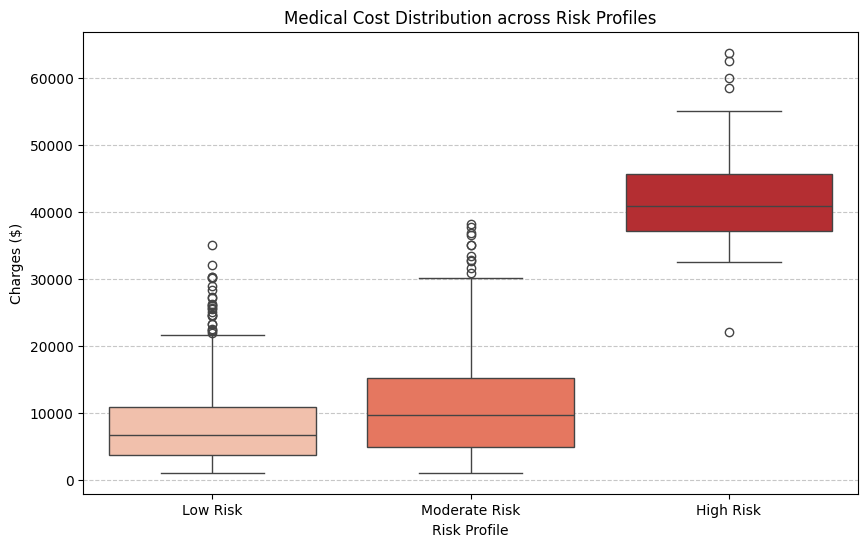

In [10]:
# Visualize cost distribution by risk profile
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_profiled, x='Risk Profile', y='charges', order=['Low Risk', 'Moderate Risk', 'High Risk'], palette='Reds')
plt.title('Medical Cost Distribution across Risk Profiles')
plt.xlabel('Risk Profile')
plt.ylabel('Charges ($)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Explanation of the Risk Profile Box Plot

The box plot visualizes how medical charges are distributed across our three constructed risk groups:

1. Low Risk (Non-Smokers, BMI under 30):
* Cost Profile: This group enjoys the lowest and most predictable charges.
* Median Cost: Sitting well under $10,000.

* Spread & Outliers: The box is very narrow, indicating high consistency. However, there are several outlier points extending upwards towards $35,000, which likely represent older individuals within this healthy category.


2. Moderate Risk (Smokers with BMI under 30 OR Non-Smokers with BMI of 30 or above):
* Cost Profile: This tier has a much wider spread, showing greater volatility in charges.
* Median Cost: Around $10,000, which is slightly higher than the Low Risk group.

* Spread: The distribution spans up to $30,000 (excluding outliers). This highlights that being a smoker or being obese independently introduces a higher likelihood of elevated medical costs.


3. High Risk (Smokers with BMI of 30 or above):
* Cost Profile: This group faces exceptionally high and severe medical charges.
* Median Cost: Exceeds $40,000, completely separated from the other two groups with no overlap in their boxes.
* Significance: This visually proves our interaction term hypothesis—when smoking and high BMI coexist, they compound risk dramatically, causing medical charges to skyrocket.

### Interactive Risk Profile Calculator

Adjust the sliders and toggles below to immediately determine an individual's custom Risk Profile and see their associated statistical metrics.

In [11]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Create widgets for the profiling criteria
calc_bmi = widgets.FloatSlider(value=28.0, min=10.0, max=60.0, step=0.1, description='BMI:')
calc_smoker = widgets.ToggleButton(value=False, description='Is Smoker', button_style='', tooltip='Click to toggle smoking status', icon='check')

calc_output = widgets.Output()

def update_profile_calc(*args):
    with calc_output:
        clear_output()

        # Use our existing logic to determine profile
        is_smoker = calc_smoker.value
        is_obese = calc_bmi.value >= 30

        if is_smoker and is_obese:
            profile = 'High Risk'
            color = 'red'
        elif is_smoker or is_obese:
            profile = 'Moderate Risk'
            color = 'orange'
        else:
            profile = 'Low Risk'
            color = 'green'

        # Fetch precalculated stats
        stats = profile_summary.loc[profile]

        print(f"Calculated Profile: {profile.upper()}")
        print(f"Historical Group Data:")
        print(f"  - Patient Count in Dataset: {int(stats['patient_count'])}")
        print(f"  - Average Historical Cost: ${stats['average_charges']:.2f}")
        print(f"  - Median Historical Cost: ${stats['median_charges']:.2f}")

# Watch for value changes
calc_bmi.observe(update_profile_calc, 'value')
calc_smoker.observe(update_profile_calc, 'value')

# Render widgets and initial calculation
calc_container = widgets.VBox([calc_bmi, calc_smoker])
display(calc_container, calc_output)
update_profile_calc()

Output()